In [2]:

# STEP 1: Import required libraries

import os
import zipfile
import glob
import pandas as pd
import numpy as np

from google.colab import files

print("All libraries imported successfully!")
print("Google Colab is ready!")


All libraries imported successfully!
Google Colab is ready!


In [3]:

# STEP 2: Upload Olist dataset ZIP

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

# Create data directory
os.makedirs("/content/data", exist_ok=True)

# Extract ZIP files
with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/data")

# Find CSV files
csv_files = glob.glob(
    "/content/data/**/*.csv",
    recursive=True
)

print("\nDataset extraction completed!")
print("Total CSV files found:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))


Saving archive (1).zip to archive (1).zip

Dataset extraction completed!
Total CSV files found: 9
product_category_name_translation.csv
olist_order_reviews_dataset.csv
olist_order_items_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_geolocation_dataset.csv
olist_customers_dataset.csv
olist_order_payments_dataset.csv
olist_sellers_dataset.csv


In [4]:

# STEP 3: LOAD ALL 9 OLIST DATASETS

import pandas as pd
import os
import glob

# Find all CSV files
csv_files = glob.glob(
    "/content/data/**/*.csv",
    recursive=True
)

# Create dictionary to store datasets
datasets = {}

# Load each CSV file
for file_path in csv_files:

    file_name = os.path.basename(file_path)

    # Create table name from filename
    table_name = file_name.replace(
        "olist_", ""
    ).replace("_dataset.csv", "").replace(
        ".csv", ""
    )

    # Read CSV
    datasets[table_name] = pd.read_csv(file_path)

    print(f"Successfully loaded: {table_name}")

print("\nAll datasets loaded successfully!")
print("Total datasets:", len(datasets))


Successfully loaded: product_category_name_translation
Successfully loaded: order_reviews
Successfully loaded: order_items
Successfully loaded: orders
Successfully loaded: products
Successfully loaded: geolocation
Successfully loaded: customers
Successfully loaded: order_payments
Successfully loaded: sellers

All datasets loaded successfully!
Total datasets: 9


In [5]:

# STEP 4: DATASET OVERVIEW

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("DATASET:", name.upper())
    print("=" * 60)

    print("Rows and Columns:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nMissing Values:")
    print(df.isnull().sum().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())



DATASET: PRODUCT_CATEGORY_NAME_TRANSLATION
Rows and Columns: (71, 2)

Column Names:
['product_category_name', 'product_category_name_english']

Missing Values:
0

Duplicate Rows:
0

DATASET: ORDER_REVIEWS
Rows and Columns: (99224, 7)

Column Names:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Missing Values:
145903

Duplicate Rows:
0

DATASET: ORDER_ITEMS
Rows and Columns: (112650, 7)

Column Names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Missing Values:
0

Duplicate Rows:
0

DATASET: ORDERS
Rows and Columns: (99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Missing Values:
4908

Duplicate Rows:
0

DATASET: PRODUCTS
Rows and Columns: (32951, 9)

Column Name

In [6]:

# STEP 5: CREATE SQLITE DATABASE

import sqlite3

# Create SQLite database
database_path = "/content/olist.db"

# Connect to database
connection = sqlite3.connect(database_path)

print("SQLite database connected successfully!")

# Convert all Pandas DataFrames into SQL tables
for table_name, df in datasets.items():

    df.to_sql(
        name=table_name,
        con=connection,
        if_exists="replace",
        index=False
    )

    print(
        f"Created table: {table_name} | Rows: {len(df)}"
    )

# Close database connection
connection.close()

print("\nDatabase created successfully!")
print("Database location:", database_path)


SQLite database connected successfully!
Created table: product_category_name_translation | Rows: 71
Created table: order_reviews | Rows: 99224
Created table: order_items | Rows: 112650
Created table: orders | Rows: 99441
Created table: products | Rows: 32951
Created table: geolocation | Rows: 1000163
Created table: customers | Rows: 99441
Created table: order_payments | Rows: 103886
Created table: sellers | Rows: 3095

Database created successfully!
Database location: /content/olist.db


In [7]:

# STEP 6: VERIFY ALL SQL TABLES

import sqlite3
import pandas as pd

# Connect to existing database
connection = sqlite3.connect("/content/olist.db")

# Retrieve all table names
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    connection
)

print("TABLES AVAILABLE IN DATABASE:")
display(tables)

print("Total SQL tables:", len(tables))


TABLES AVAILABLE IN DATABASE:


,name
0,customers
1,geolocation
2,order_items
3,order_payments
4,order_reviews
5,orders
6,product_category_name_translation
7,products
8,sellers


Total SQL tables: 9


In [8]:

# STEP 7: FIRST SQL QUERY

query = """
SELECT *
FROM customers
LIMIT 10;
"""

customer_data = pd.read_sql_query(
    query,
    connection
)

display(customer_data)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [9]:

# STEP 8: COUNT TOTAL CUSTOMERS

query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

result = pd.read_sql_query(query, connection)

display(result)


,total_customers
0,99441


In [10]:

# STEP 9: SQL ANALYSIS CONNECTION

import sqlite3
import pandas as pd

connection = sqlite3.connect("/content/olist.db")

print("SQL connection established!")


SQL connection established!


QUERY 1 — Monthly Revenue Analysis
Business Question Q1
Question: How has revenue grown month over month?
1. Business understanding
Imagine you're working as a Data Analyst at Olist.

Management wants to know:
- How much revenue was generated each month?
- Which month generated the highest revenue?
- Is revenue increasing or decreasing over time?
For this analysis, we'll use:
- orders table
- order_items table
We'll calculate revenue using the product price in order_items.
2. SQL concepts we'll learn
SQL concept	Purpose
SELECT	Select columns
JOIN	Connect tables
SUM()	Calculate total revenue
GROUP BY	Group by month
ORDER BY	Sort results

In [11]:

# QUERY 1: MONTHLY REVENUE ANALYSIS

query_1 = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    ROUND(SUM(oi.price), 2) AS monthly_revenue,
    COUNT(DISTINCT o.order_id) AS total_orders

FROM orders o

JOIN order_items oi
    ON o.order_id = oi.order_id

WHERE o.order_status = 'delivered'

GROUP BY strftime('%Y-%m', o.order_purchase_timestamp)

ORDER BY order_month;
"""

monthly_revenue = pd.read_sql_query(
    query_1,
    connection
)

display(monthly_revenue)


,order_month,monthly_revenue,total_orders
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653
5,2017-03,359198.85,2546
6,2017-04,340669.68,2303
7,2017-05,489338.25,3546
8,2017-06,421923.37,3135
9,2017-07,481604.52,3872


A. SELECT

In [13]:
query_1 = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    ROUND(SUM(oi.price), 2) AS monthly_revenue,
    COUNT(DISTINCT o.order_id) AS total_orders
FROM orders AS o
JOIN order_items AS oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY strftime('%Y-%m', o.order_purchase_timestamp)
ORDER BY order_month;
"""

monthly_revenue = pd.read_sql_query(query_1, connection)

display(monthly_revenue)

,order_month,monthly_revenue,total_orders
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653
5,2017-03,359198.85,2546
6,2017-04,340669.68,2303
7,2017-05,489338.25,3546
8,2017-06,421923.37,3135
9,2017-07,481604.52,3872


Extracts the year and month from the purchase timestamp.

B. JOIN

In [16]:
query_B = """
SELECT
    p.product_category_name AS category,
    ROUND(SUM(oi.price), 2) AS total_revenue
FROM order_items AS oi
JOIN products AS p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

result_B = pd.read_sql_query(query_B, connection)
display(result_B)

,category,total_revenue
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32
5,moveis_decoracao,729762.49
6,cool_stuff,635290.85
7,utilidades_domesticas,632248.66
8,automotivo,592720.11
9,ferramentas_jardim,485256.46


Top 10 States by Revenue

In [17]:
query_C = """
SELECT
    c.customer_state AS state,
    ROUND(SUM(oi.price), 2) AS total_revenue
FROM orders AS o
JOIN customers AS c
    ON o.customer_id = c.customer_id
JOIN order_items AS oi
    ON o.order_id = oi.order_id
GROUP BY c.customer_state
ORDER BY total_revenue DESC
LIMIT 10;
"""

result_C = pd.read_sql_query(query_C, connection)
display(result_C)

,state,total_revenue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31


Average Delivery Days by State

In [18]:
query_D = """
SELECT
    c.customer_state AS state,
    ROUND(
        AVG(
            julianday(o.order_delivered_customer_date)
            - julianday(o.order_purchase_timestamp)
        ), 2
    ) AS average_delivery_days
FROM orders AS o
JOIN customers AS c
    ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY average_delivery_days ASC;
"""

result_D = pd.read_sql_query(query_D, connection)
display(result_D)

,state,average_delivery_days
0,SP,8.76
1,PR,11.99
2,MG,12.01
3,DF,12.97
4,SC,14.95
5,RS,15.30
6,RJ,15.31
7,GO,15.61
8,MS,15.62
9,ES,15.79


Revenue by Payment Type

In [19]:
query_E = """
SELECT
    payment_type,
    ROUND(SUM(payment_value), 2) AS total_payment,
    COUNT(*) AS total_transactions
FROM order_payments
GROUP BY payment_type
ORDER BY total_payment DESC;
"""

result_E = pd.read_sql_query(query_E, connection)
display(result_E)

,payment_type,total_payment,total_transactions
0,credit_card,12542084.19,76795
1,boleto,2869361.27,19784
2,voucher,379436.87,5775
3,debit_card,217989.79,1529
4,not_defined,0.00,3


In [22]:
from google.colab import files

uploaded = files.upload()

Saving queries.sql to queries.sql


In [23]:
import sqlite3
import pandas as pd

# Connect to the database
connection = sqlite3.connect("/content/olist.db")

# Read the SQL file
with open("queries.sql", "r", encoding="utf-8") as file:
    sql_text = file.read()

# Split SQL statements
queries = [
    q.strip()
    for q in sql_text.split(";")
    if q.strip()
]

# Execute each query
for i, query in enumerate(queries, start=1):

    result = pd.read_sql_query(query, connection)

    print(f"\nQUERY {i} RESULT")
    display(result)

print("All SQL queries executed successfully!")


QUERY 1 RESULT


,order_month,monthly_revenue,total_orders
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653
5,2017-03,359198.85,2546
6,2017-04,340669.68,2303
7,2017-05,489338.25,3546
8,2017-06,421923.37,3135
9,2017-07,481604.52,3872



QUERY 2 RESULT


,category,total_revenue
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32
5,moveis_decoracao,729762.49
6,cool_stuff,635290.85
7,utilidades_domesticas,632248.66
8,automotivo,592720.11
9,ferramentas_jardim,485256.46



QUERY 3 RESULT


,state,total_revenue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31



QUERY 4 RESULT


,state,average_delivery_days
0,SP,8.76
1,PR,11.99
2,MG,12.01
3,DF,12.97
4,SC,14.95
5,RS,15.30
6,RJ,15.31
7,GO,15.61
8,MS,15.62
9,ES,15.79



QUERY 5 RESULT


,payment_type,total_payment,total_transactions
0,credit_card,12542084.19,76795
1,boleto,2869361.27,19784
2,voucher,379436.87,5775
3,debit_card,217989.79,1529
4,not_defined,0.00,3


All SQL queries executed successfully!


In [24]:
import sqlite3
import pandas as pd
import os

# Step 1: Check whether the database exists
database_path = "/content/olist.db"

if not os.path.exists(database_path):
    raise FileNotFoundError(
        "Olist database not found. Please recreate the database first."
    )

# Step 2: Connect to SQLite
connection = sqlite3.connect(database_path)

# Step 3: Check whether SQL file was uploaded
if not os.path.exists("queries.sql"):
    raise FileNotFoundError(
        "queries.sql not found. Please upload the file again."
    )

# Step 4: Read SQL file
with open("queries.sql", "r", encoding="utf-8") as file:
    sql_text = file.read()

# Step 5: Execute all queries
queries = [
    q.strip()
    for q in sql_text.split(";")
    if q.strip()
]

sql_results = {}

for i, query in enumerate(queries, start=1):
    result = pd.read_sql_query(query, connection)

    sql_results[f"Query_{i}"] = result

    print(f"\nQUERY {i} RESULT")
    print("=" * 50)
    display(result)

print("\nAll saved SQL queries executed successfully!")
print("Total queries executed:", len(sql_results))


QUERY 1 RESULT


,order_month,monthly_revenue,total_orders
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653
5,2017-03,359198.85,2546
6,2017-04,340669.68,2303
7,2017-05,489338.25,3546
8,2017-06,421923.37,3135
9,2017-07,481604.52,3872



QUERY 2 RESULT


,category,total_revenue
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32
5,moveis_decoracao,729762.49
6,cool_stuff,635290.85
7,utilidades_domesticas,632248.66
8,automotivo,592720.11
9,ferramentas_jardim,485256.46



QUERY 3 RESULT


,state,total_revenue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31



QUERY 4 RESULT


,state,average_delivery_days
0,SP,8.76
1,PR,11.99
2,MG,12.01
3,DF,12.97
4,SC,14.95
5,RS,15.30
6,RJ,15.31
7,GO,15.61
8,MS,15.62
9,ES,15.79



QUERY 5 RESULT


,payment_type,total_payment,total_transactions
0,credit_card,12542084.19,76795
1,boleto,2869361.27,19784
2,voucher,379436.87,5775
3,debit_card,217989.79,1529
4,not_defined,0.00,3



All saved SQL queries executed successfully!
Total queries executed: 5


In [25]:
import pandas as pd
import numpy as np
import os
import glob

# Find all CSV files
csv_files = glob.glob(
    "/content/data/**/*.csv",
    recursive=True
)

# Create dictionary for datasets
datasets = {}

for file_path in csv_files:

    file_name = os.path.basename(file_path)

    table_name = (
        file_name
        .replace("olist_", "")
        .replace("_dataset.csv", "")
        .replace(".csv", "")
    )

    datasets[table_name] = pd.read_csv(file_path)

    print(f"Loaded: {table_name}")

print("\nTotal datasets loaded:", len(datasets))

Loaded: product_category_name_translation
Loaded: order_reviews
Loaded: order_items
Loaded: orders
Loaded: products
Loaded: geolocation
Loaded: customers
Loaded: order_payments
Loaded: sellers

Total datasets loaded: 9


In [26]:
# Missing values and duplicate analysis

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("DATASET:", name.upper())
    print("=" * 60)

    print("Total Rows:", df.shape[0])
    print("Total Columns:", df.shape[1])

    print("\nMissing Values by Column:")
    missing = df.isnull().sum()
    print(missing[missing > 0])

    print("\nTotal Missing Values:", df.isnull().sum().sum())

    print("Duplicate Rows:", df.duplicated().sum())



DATASET: PRODUCT_CATEGORY_NAME_TRANSLATION
Total Rows: 71
Total Columns: 2

Missing Values by Column:
Series([], dtype: int64)

Total Missing Values: 0
Duplicate Rows: 0

DATASET: ORDER_REVIEWS
Total Rows: 99224
Total Columns: 7

Missing Values by Column:
review_comment_title      87656
review_comment_message    58247
dtype: int64

Total Missing Values: 145903
Duplicate Rows: 0

DATASET: ORDER_ITEMS
Total Rows: 112650
Total Columns: 7

Missing Values by Column:
Series([], dtype: int64)

Total Missing Values: 0
Duplicate Rows: 0

DATASET: ORDERS
Total Rows: 99441
Total Columns: 8

Missing Values by Column:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Total Missing Values: 4908
Duplicate Rows: 0

DATASET: PRODUCTS
Total Rows: 32951
Total Columns: 9

Missing Values by Column:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            

In [27]:
# Step 1: Create a copy of the orders dataset
orders_clean = datasets["orders"].copy()

# Step 2: Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

# Step 3: Remove duplicate order records
orders_clean = orders_clean.drop_duplicates(
    subset=["order_id"]
)

# Step 4: Display cleaned dataset information
print("Orders dataset cleaned successfully!")

print("\nDataset Shape:", orders_clean.shape)

print("\nDate Column Data Types:")
print(orders_clean[date_columns].dtypes)

print("\nMissing Values:")
print(orders_clean[date_columns].isnull().sum())

print("\nDuplicate Order IDs:",
      orders_clean["order_id"].duplicated().sum())

display(orders_clean.head())

Orders dataset cleaned successfully!

Dataset Shape: (99441, 8)

Date Column Data Types:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Missing Values:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplicate Order IDs: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [28]:
# Create clean copies of the datasets

customers_clean = datasets["customers"].copy()
products_clean = datasets["products"].copy()
order_items_clean = datasets["order_items"].copy()
payments_clean = datasets["order_payments"].copy()
reviews_clean = datasets["order_reviews"].copy()

# 1. Remove duplicate records using primary keys
customers_clean = customers_clean.drop_duplicates(
    subset=["customer_id"]
)

products_clean = products_clean.drop_duplicates(
    subset=["product_id"]
)

# Order items use a combination of order_id and order_item_id
order_items_clean = order_items_clean.drop_duplicates(
    subset=["order_id", "order_item_id"]
)

payments_clean = payments_clean.drop_duplicates(
    subset=["order_id", "payment_sequential"]
)

reviews_clean = reviews_clean.drop_duplicates(
    subset=["review_id"]
)

# 2. Convert review dates into datetime format
review_date_columns = [
    "review_creation_date",
    "review_answer_timestamp"
]

for column in review_date_columns:
    reviews_clean[column] = pd.to_datetime(
        reviews_clean[column],
        errors="coerce"
    )

# 3. Check cleaned datasets
cleaned_datasets = {
    "Customers": customers_clean,
    "Products": products_clean,
    "Order Items": order_items_clean,
    "Payments": payments_clean,
    "Reviews": reviews_clean
}

for name, df in cleaned_datasets.items():

    print("\n" + "=" * 45)
    print(name.upper())
    print("=" * 45)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Duplicate Rows:", df.duplicated().sum())

print("\nAll selected datasets cleaned successfully!")


CUSTOMERS
Rows: 99441
Columns: 5
Duplicate Rows: 0

PRODUCTS
Rows: 32951
Columns: 9
Duplicate Rows: 0

ORDER ITEMS
Rows: 112650
Columns: 7
Duplicate Rows: 0

PAYMENTS
Rows: 103886
Columns: 5
Duplicate Rows: 0

REVIEWS
Rows: 98410
Columns: 7
Duplicate Rows: 0

All selected datasets cleaned successfully!


In [29]:
# STEP 1: Start with the cleaned orders dataset
orders_features = orders_clean.copy()

# STEP 2: Calculate delivery days
orders_features["delivery_days"] = (
    orders_features["order_delivered_customer_date"]
    - orders_features["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# STEP 3: Identify late deliveries
orders_features["is_late"] = np.where(
    orders_features["order_delivered_customer_date"].notna()
    & orders_features["order_estimated_delivery_date"].notna()
    & (
        orders_features["order_delivered_customer_date"]
        > orders_features["order_estimated_delivery_date"]
    ),
    1,
    0
)

# STEP 4: Extract purchase month
orders_features["order_month"] = (
    orders_features["order_purchase_timestamp"].dt.month
)

# STEP 5: Extract purchase weekday
orders_features["order_weekday"] = (
    orders_features["order_purchase_timestamp"].dt.day_name()
)

# STEP 6: Extract purchase hour
orders_features["order_hour"] = (
    orders_features["order_purchase_timestamp"].dt.hour
)

# STEP 7: Calculate total order value
order_value = (
    order_items_clean
    .groupby("order_id", as_index=False)
    .agg(
        product_price=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

order_value["total_order_value"] = (
    order_value["product_price"] + order_value["freight_value"]
)

# Merge order value into orders
orders_features = orders_features.merge(
    order_value[["order_id", "total_order_value"]],
    on="order_id",
    how="left"
)

# STEP 8: Display results
print("Feature engineering completed successfully!")

print("\nNew Features:")
print([
    "delivery_days",
    "is_late",
    "order_month",
    "order_weekday",
    "order_hour",
    "total_order_value"
])

display(orders_features.head(10))

print("\nDataset Shape:", orders_features.shape)

Feature engineering completed successfully!

New Features:
['delivery_days', 'is_late', 'order_month', 'order_weekday', 'order_hour', 'total_order_value']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,order_month,order_weekday,order_hour,total_order_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,0,10,Monday,10,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,0,7,Tuesday,20,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,0,8,Wednesday,8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,0,11,Saturday,19,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,0,2,Tuesday,21,28.62
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,16.542245,0,7,Sunday,21,175.26
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09,NaN,0,4,Tuesday,12,65.95
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,9.989826,0,5,Tuesday,13,75.16
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,9.818762,0,1,Monday,18,35.95
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,18.221852,0,7,Saturday,11,169.76



Dataset Shape: (99441, 14)


In [30]:
# STEP 1: Translate product categories into English

translation = datasets["product_category_name_translation"].copy()

products_translated = products_clean.merge(
    translation,
    on="product_category_name",
    how="left"
)

products_translated["product_category_name_english"] = (
    products_translated["product_category_name_english"]
    .fillna(products_translated["product_category_name"])
    .fillna("Unknown")
)

print("Product categories translated successfully!")


# STEP 2: Prepare customer information

customer_info = customers_clean[
    ["customer_id", "customer_unique_id",
     "customer_city", "customer_state"]
].copy()


# STEP 3: Calculate average review score per order

review_summary = (
    reviews_clean
    .groupby("order_id", as_index=False)
    .agg(avg_review_score=("review_score", "mean"))
)


# STEP 4: Calculate payment information per order

payment_summary = (
    payments_clean
    .groupby("order_id", as_index=False)
    .agg(
        total_payment=("payment_value", "sum"),
        payment_installments=("payment_installments", "max")
    )
)


# STEP 5: Merge all information into the order-level dataset

olist_clean = orders_features.merge(
    customer_info,
    on="customer_id",
    how="left"
)

olist_clean = olist_clean.merge(
    review_summary,
    on="order_id",
    how="left"
)

olist_clean = olist_clean.merge(
    payment_summary,
    on="order_id",
    how="left"
)


# STEP 6: Display final dataset information

print("\nFINAL DATASET CREATED SUCCESSFULLY!")
print("Rows:", olist_clean.shape[0])
print("Columns:", olist_clean.shape[1])

print("\nFinal Columns:")
print(olist_clean.columns.tolist())

display(olist_clean.head(10))

Product categories translated successfully!

FINAL DATASET CREATED SUCCESSFULLY!
Rows: 99441
Columns: 20

Final Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_days', 'is_late', 'order_month', 'order_weekday', 'order_hour', 'total_order_value', 'customer_unique_id', 'customer_city', 'customer_state', 'avg_review_score', 'total_payment', 'payment_installments']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,order_month,order_weekday,order_hour,total_order_value,customer_unique_id,customer_city,customer_state,avg_review_score,total_payment,payment_installments
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,0,10,Monday,10,38.71,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,4.0,38.71,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,0,7,Tuesday,20,141.46,af07308b275d755c9edb36a90c618231,barreiras,BA,4.0,141.46,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,0,8,Wednesday,8,179.12,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,5.0,179.12,3.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,0,11,Saturday,19,72.20,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,5.0,72.20,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,0,2,Tuesday,21,28.62,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,5.0,28.62,1.0
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,16.542245,0,7,Sunday,21,175.26,80bb27c7c16e8f973207a5086ab329e2,congonhinhas,PR,4.0,175.26,6.0
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09,NaN,0,4,Tuesday,12,65.95,36edbb3fb164b1f16485364b6fb04c73,santa rosa,RS,2.0,65.95,1.0
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,9.989826,0,5,Tuesday,13,75.16,932afa1e708222e5821dac9cd5db4cae,nilopolis,RJ,5.0,75.16,3.0
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,9.818762,0,1,Monday,18,35.95,39382392765b6dc74812866ee5ee92a7,faxinalzinho,RS,1.0,35.95,1.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,18.221852,0,7,Saturday,11,169.76,299905e3934e9e181bfb2e164dd4b4f8,sorocaba,SP,5.0,169.76,1.0


In [31]:
# Save the final cleaned dataset
output_path = "/content/olist_clean.csv"

olist_clean.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

print("Cleaned dataset saved successfully!")
print("File:", output_path)
print("Rows:", len(olist_clean))
print("Columns:", len(olist_clean.columns))
print("File size:", round(os.path.getsize(output_path) / (1024 * 1024), 2), "MB")

Cleaned dataset saved successfully!
File: /content/olist_clean.csv
Rows: 99441
Columns: 20
File size: 25.55 MB


In [32]:
from google.colab import files

files.download("/content/olist_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Import visualization libraries

In [33]:
# DATA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import pandas as pd
import numpy as np
import os

# Set visualization style
sns.set_theme(style="whitegrid")

# Create folder for saving charts
os.makedirs("/content/images", exist_ok=True)

# Check cleaned dataset
print("Visualization libraries imported successfully!")

print("\nDataset Information:")
print("Rows:", olist_clean.shape[0])
print("Columns:", olist_clean.shape[1])

print("\nAvailable columns:")
print(olist_clean.columns.tolist())

print("\nImages folder created successfully!")

Visualization libraries imported successfully!

Dataset Information:
Rows: 99441
Columns: 20

Available columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_days', 'is_late', 'order_month', 'order_weekday', 'order_hour', 'total_order_value', 'customer_unique_id', 'customer_city', 'customer_state', 'avg_review_score', 'total_payment', 'payment_installments']

Images folder created successfully!


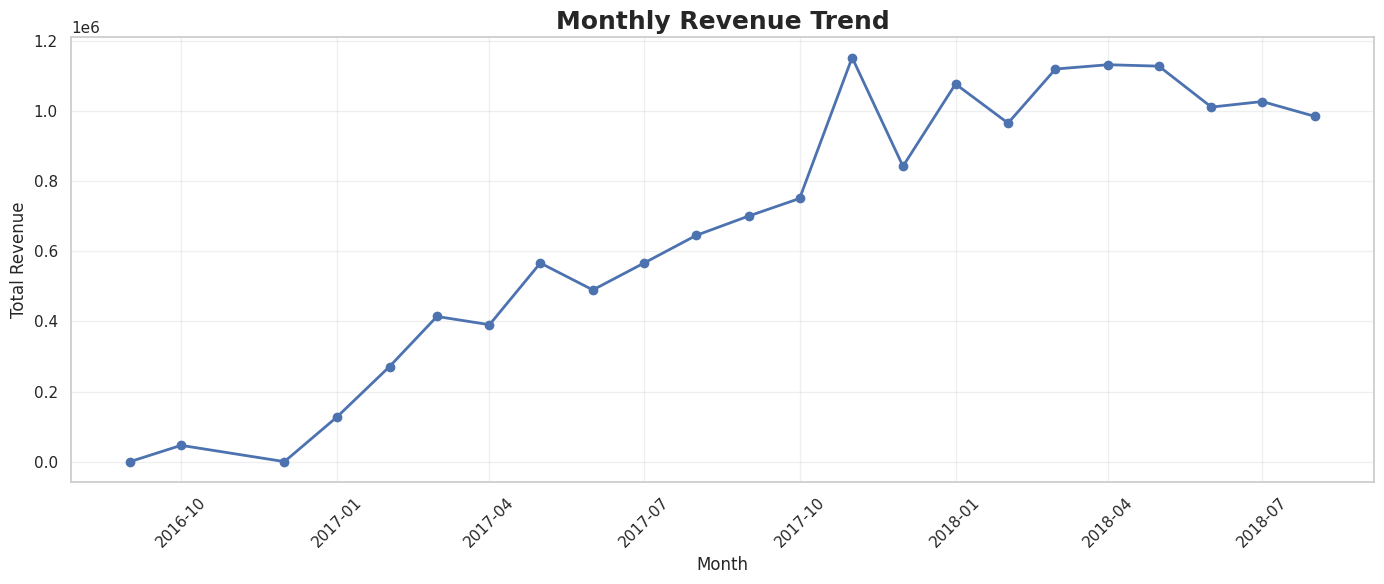

Chart 1 created and saved successfully!


In [34]:

# CHART 1: MONTHLY REVENUE TREND

import matplotlib.pyplot as plt
import pandas as pd
import os

# Create images folder if it does not exist
os.makedirs("/content/images", exist_ok=True)

# Prepare monthly revenue data
monthly_sales = (
    olist_clean[
        olist_clean["order_status"] == "delivered"
    ]
    .dropna(subset=["order_purchase_timestamp"])
    .groupby(
        olist_clean["order_purchase_timestamp"].dt.to_period("M")
    )["total_order_value"]
    .sum()
    .reset_index()
)

# Convert monthly period into datetime
monthly_sales["order_purchase_timestamp"] = (
    monthly_sales["order_purchase_timestamp"].dt.to_timestamp()
)

# Create the chart
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_purchase_timestamp"],
    monthly_sales["total_order_value"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Revenue Trend",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "/content/images/chart_01_monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 1 created and saved successfully!")


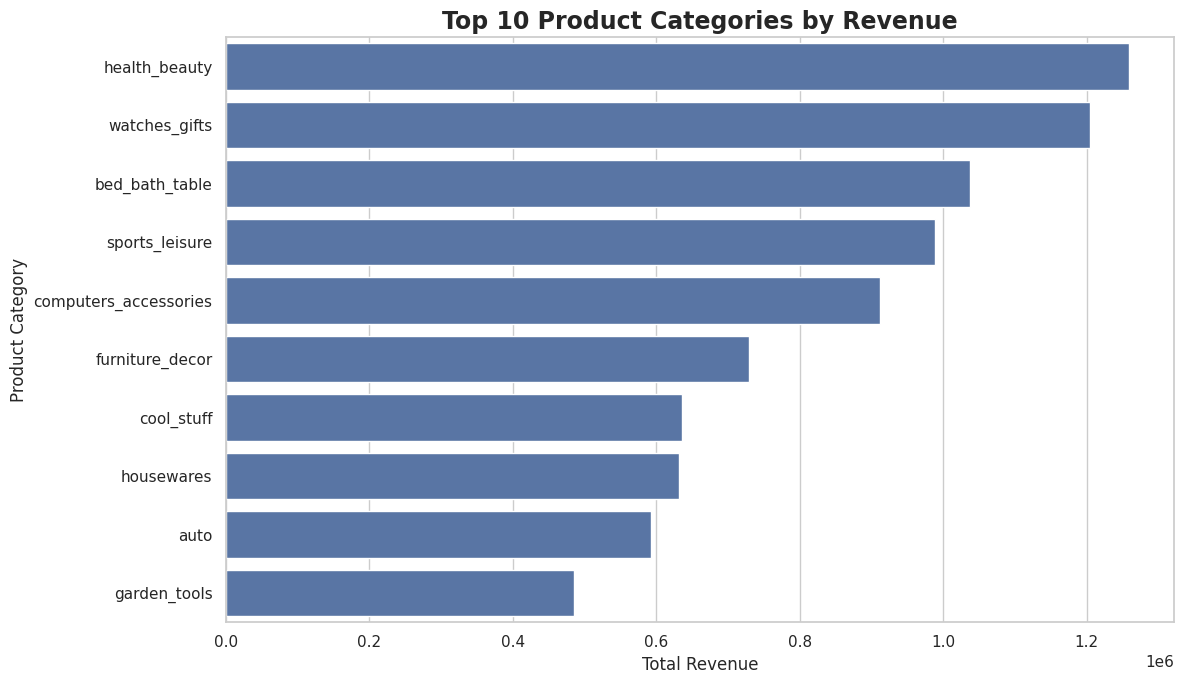

Chart 2 created and saved successfully!


,category,total_revenue
44,health_beauty,1258681.34
73,watches_gifts,1205005.68
8,bed_bath_table,1036988.68
68,sports_leisure,988048.97
16,computers_accessories,911954.32
40,furniture_decor,729762.49
21,cool_stuff,635290.85
50,housewares,632248.66
6,auto,592720.11
43,garden_tools,485256.46


In [35]:

# CHART 2: TOP 10 PRODUCT CATEGORIES BY REVENUE

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Create images folder
os.makedirs("/content/images", exist_ok=True)

# Calculate revenue by product category
category_revenue = (
    order_items_clean
    .merge(
        products_translated[
            ["product_id", "product_category_name_english"]
        ],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name_english", as_index=False)
    ["price"]
    .sum()
)

# Rename columns
category_revenue.columns = ["category", "total_revenue"]

# Select top 10 categories
top_10_categories = (
    category_revenue
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_categories,
    x="total_revenue",
    y="category"
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Total Revenue", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

plt.tight_layout()

# Save chart
plt.savefig(
    "/content/images/chart_02_top_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 2 created and saved successfully!")

display(top_10_categories)


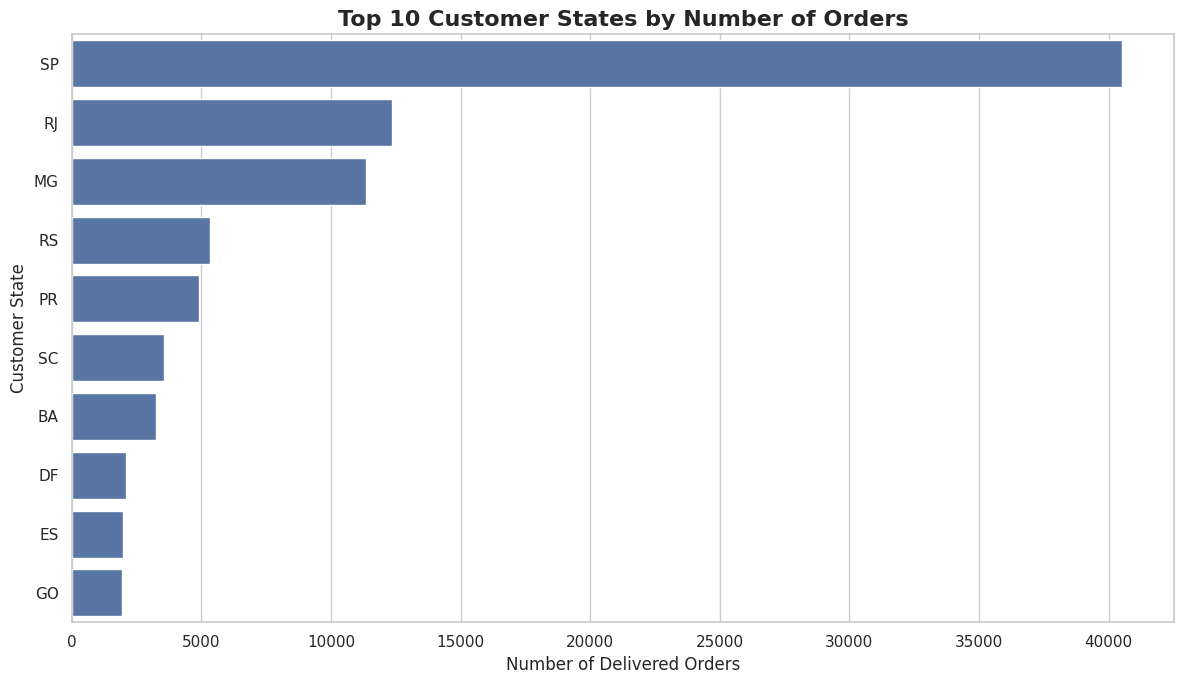

Chart 3 saved successfully!


,customer_state,total_orders
25,SP,40501
18,RJ,12350
10,MG,11354
22,RS,5345
17,PR,4923
23,SC,3546
4,BA,3256
6,DF,2080
7,ES,1995
8,GO,1957


In [36]:

# CHART 3: TOP 10 CUSTOMER STATES BY ORDERS

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Merge orders with customer information
state_orders = orders_clean.merge(
    customers_clean[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Count delivered orders by state
state_summary = (
    state_orders[state_orders["order_status"] == "delivered"]
    .groupby("customer_state")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("total_orders", ascending=False)
    .head(10)
)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_summary,
    x="total_orders",
    y="customer_state"
)

plt.title("Top 10 Customer States by Number of Orders",
          fontsize=16, fontweight="bold")
plt.xlabel("Number of Delivered Orders")
plt.ylabel("Customer State")
plt.tight_layout()

plt.savefig(
    "/content/images/chart_03_top_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 3 saved successfully!")
display(state_summary)


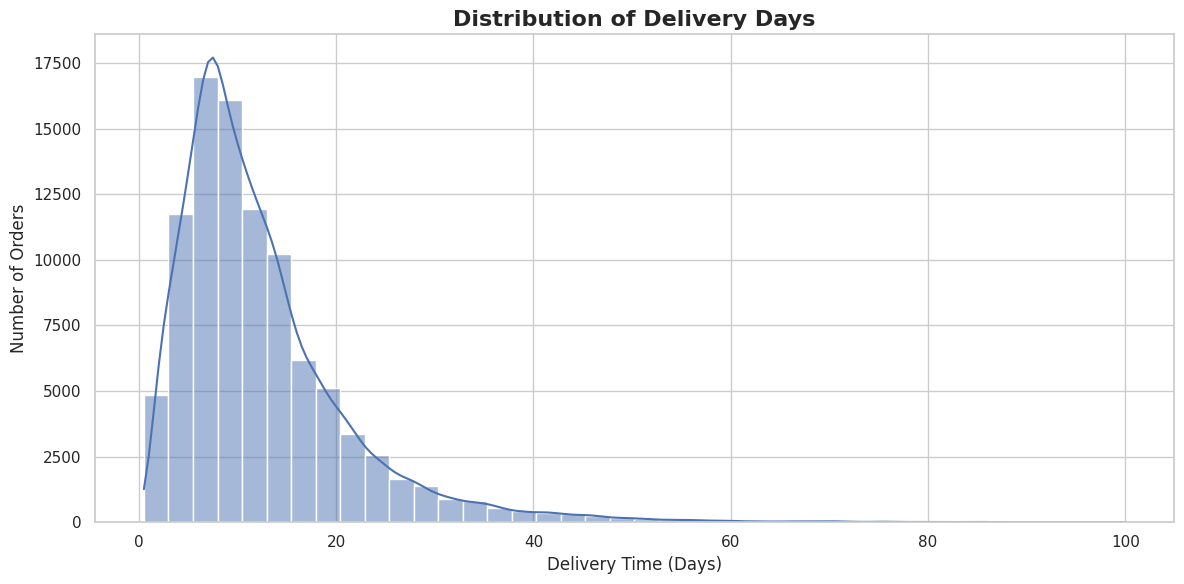

Chart 4 saved successfully!
Average delivery days: 12.47
Median delivery days: 10.21


In [37]:

# CHART 4: DELIVERY DAYS DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Select valid delivery durations
delivery_data = orders_features[
    orders_features["delivery_days"].notna()
    & (orders_features["delivery_days"] >= 0)
    & (orders_features["delivery_days"] <= 100)
].copy()

# Create histogram with KDE
plt.figure(figsize=(12, 6))

sns.histplot(
    data=delivery_data,
    x="delivery_days",
    bins=40,
    kde=True
)

plt.title("Distribution of Delivery Days",
          fontsize=16, fontweight="bold")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig(
    "/content/images/chart_04_delivery_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 4 saved successfully!")

print(
    "Average delivery days:",
    round(delivery_data["delivery_days"].mean(), 2)
)

print(
    "Median delivery days:",
    round(delivery_data["delivery_days"].median(), 2)
)


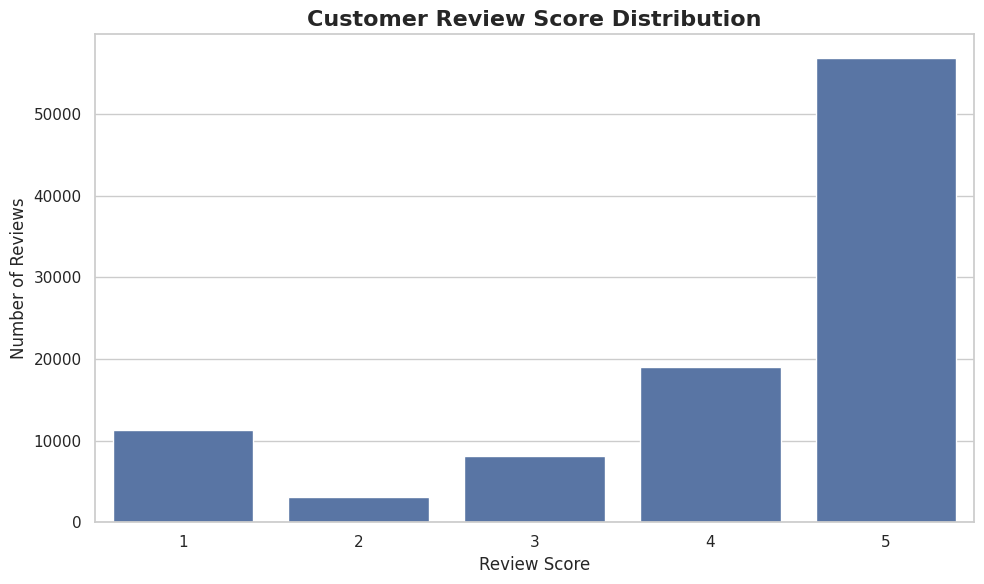

Chart 5 saved successfully!
Average Review Score: 4.09


,review_score,total_reviews
0,1,11282
1,2,3114
2,3,8097
3,4,19007
4,5,56910


In [38]:

# CHART 5: CUSTOMER REVIEW SCORE DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Select valid review scores
review_data = reviews_clean[
    reviews_clean["review_score"].notna()
].copy()

# Convert scores to integer
review_data["review_score"] = (
    review_data["review_score"].astype(int)
)

# Count review scores
review_summary = (
    review_data["review_score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .reset_index()
)

review_summary.columns = ["review_score", "total_reviews"]

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=review_summary,
    x="review_score",
    y="total_reviews"
)

plt.title("Customer Review Score Distribution",
          fontsize=16, fontweight="bold")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])
plt.tight_layout()

plt.savefig(
    "/content/images/chart_05_review_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 5 saved successfully!")

print(
    "Average Review Score:",
    round(review_data["review_score"].mean(), 2)
)

display(review_summary)


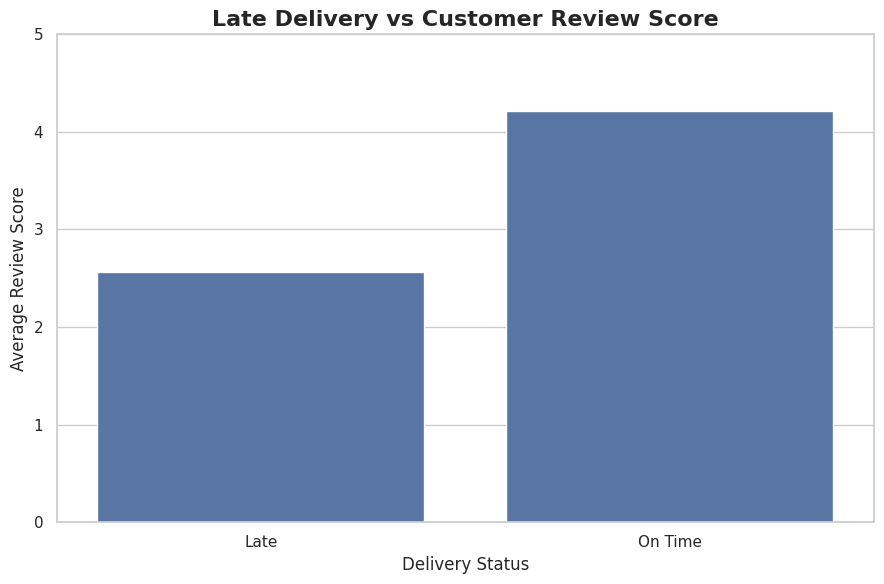

Chart 6 saved successfully!


,delivery_status,avg_review_score
0,Late,2.565309
1,On Time,4.216905


In [39]:

# CHART 6: LATE DELIVERY VS REVIEW SCORE

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Merge orders and reviews
late_review_data = orders_features[
    ["order_id", "is_late"]
].merge(
    reviews_clean[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

# Create readable labels
late_review_data["delivery_status"] = (
    late_review_data["is_late"]
    .map({0: "On Time", 1: "Late"})
)

# Calculate average review score
late_review_summary = (
    late_review_data
    .groupby("delivery_status", as_index=False)
    .agg(avg_review_score=("review_score", "mean"))
)

# Create chart
plt.figure(figsize=(9, 6))

sns.barplot(
    data=late_review_summary,
    x="delivery_status",
    y="avg_review_score"
)

plt.title(
    "Late Delivery vs Customer Review Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.tight_layout()

plt.savefig(
    "/content/images/chart_06_late_vs_review.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 6 saved successfully!")
display(late_review_summary)


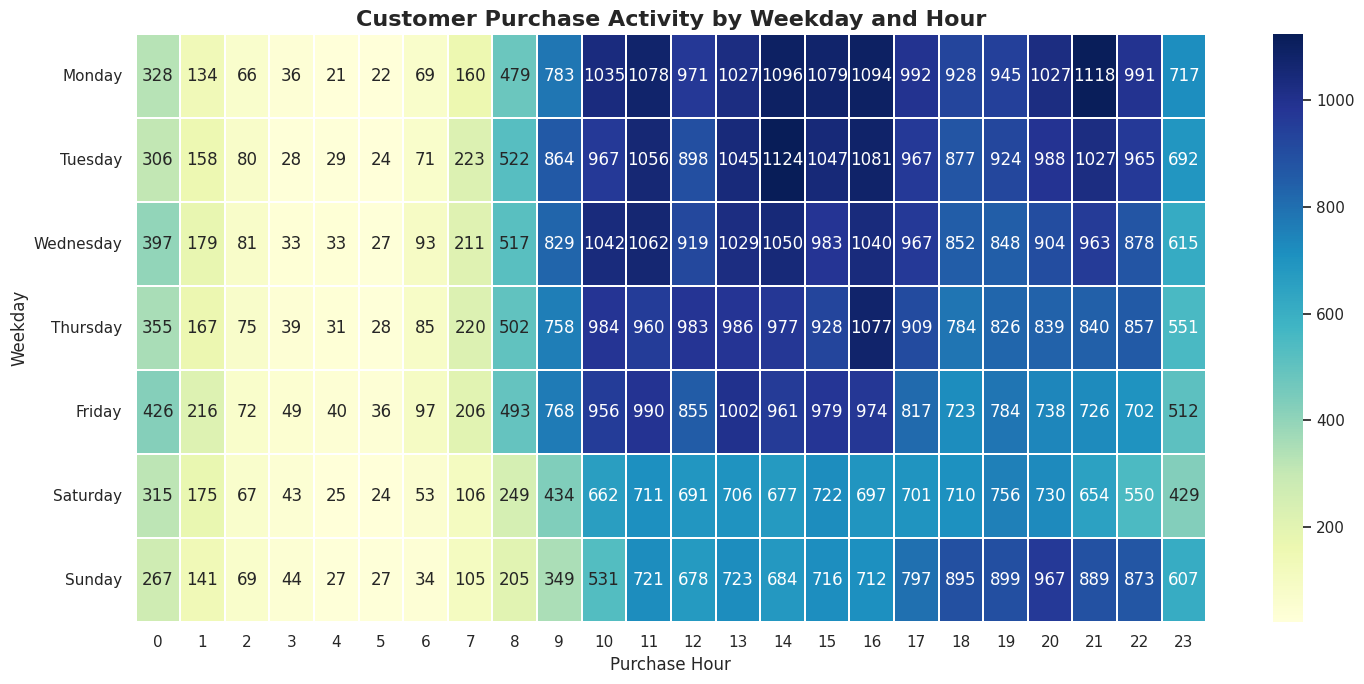

Chart 7 saved successfully!


In [40]:

# CHART 7: WEEKDAY AND HOUR HEATMAP

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Define weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Prepare purchase activity
activity_data = orders_features.dropna(
    subset=["order_weekday", "order_hour"]
).copy()

# Create pivot table
activity_pivot = pd.crosstab(
    activity_data["order_weekday"],
    activity_data["order_hour"]
)

# Arrange weekdays correctly
activity_pivot = activity_pivot.reindex(
    weekday_order,
    fill_value=0
)

# Create heatmap
plt.figure(figsize=(15, 7))

sns.heatmap(
    activity_pivot,
    cmap="YlGnBu",
    linewidths=0.3,
    annot=True,
    fmt="d"
)

plt.title(
    "Customer Purchase Activity by Weekday and Hour",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Purchase Hour")
plt.ylabel("Weekday")
plt.tight_layout()

plt.savefig(
    "/content/images/chart_07_weekday_hour_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 7 saved successfully!")


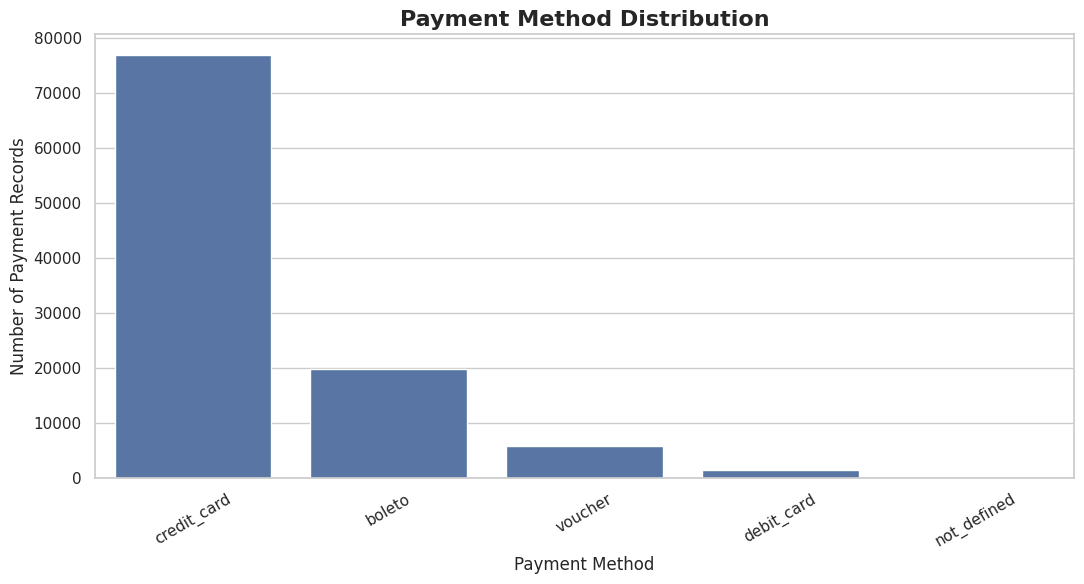

Chart 8 saved successfully!


,payment_type,total_transactions,total_payment_value
1,credit_card,76795,12542084.19
0,boleto,19784,2869361.27
4,voucher,5775,379436.87
2,debit_card,1529,217989.79
3,not_defined,3,0.00


In [41]:

# CHART 8: PAYMENT METHOD DISTRIBUTION

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Summarize payment methods
payment_summary = (
    payments_clean
    .groupby("payment_type", as_index=False)
    .agg(
        total_transactions=("payment_type", "count"),
        total_payment_value=("payment_value", "sum")
    )
    .sort_values("total_transactions", ascending=False)
)

# Create bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_summary,
    x="payment_type",
    y="total_transactions"
)

plt.title(
    "Payment Method Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Payment Records")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "/content/images/chart_08_payment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 8 saved successfully!")
display(payment_summary)


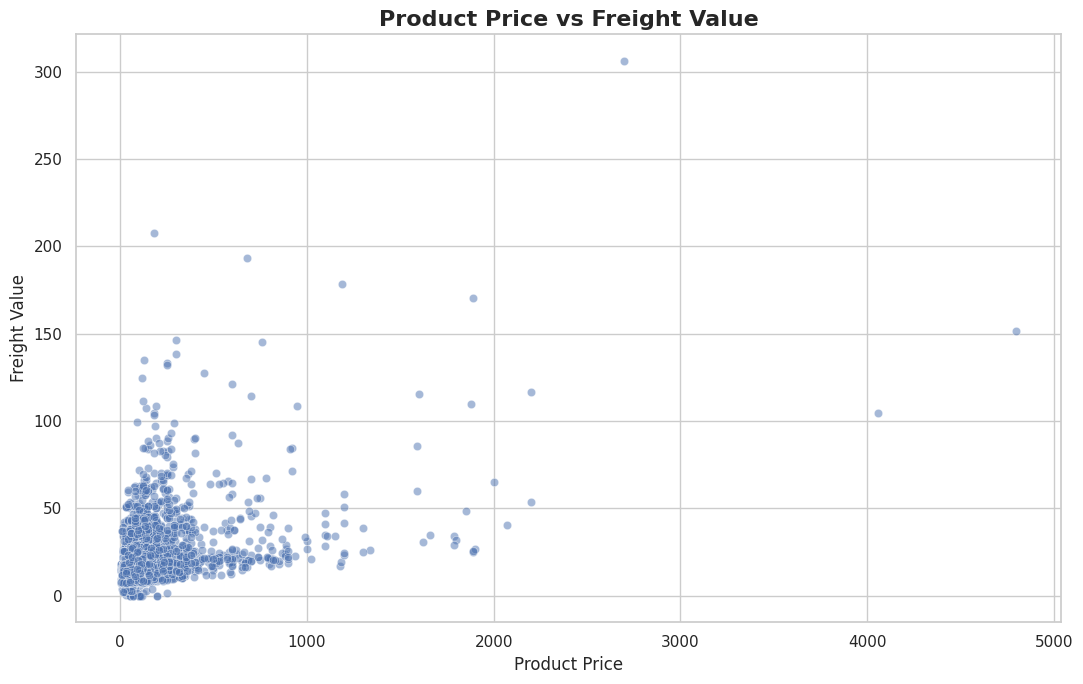

Chart 9 saved successfully!
Correlation: 0.414


In [42]:

# CHART 9: PRODUCT PRICE VS FREIGHT VALUE

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Select required columns
price_freight_data = order_items_clean[
    ["price", "freight_value"]
].dropna().copy()

# Remove invalid negative values
price_freight_data = price_freight_data[
    (price_freight_data["price"] >= 0) &
    (price_freight_data["freight_value"] >= 0)
]

# Sample data for a readable chart
sample_size = min(5000, len(price_freight_data))

price_freight_sample = price_freight_data.sample(
    n=sample_size,
    random_state=42
)

# Create scatter plot
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=price_freight_sample,
    x="price",
    y="freight_value",
    alpha=0.5
)

plt.title(
    "Product Price vs Freight Value",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Price")
plt.ylabel("Freight Value")
plt.tight_layout()

plt.savefig(
    "/content/images/chart_09_price_vs_freight.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 9 saved successfully!")

print(
    "Correlation:",
    round(
        price_freight_data["price"].corr(
            price_freight_data["freight_value"]
        ),
        3
    )
)


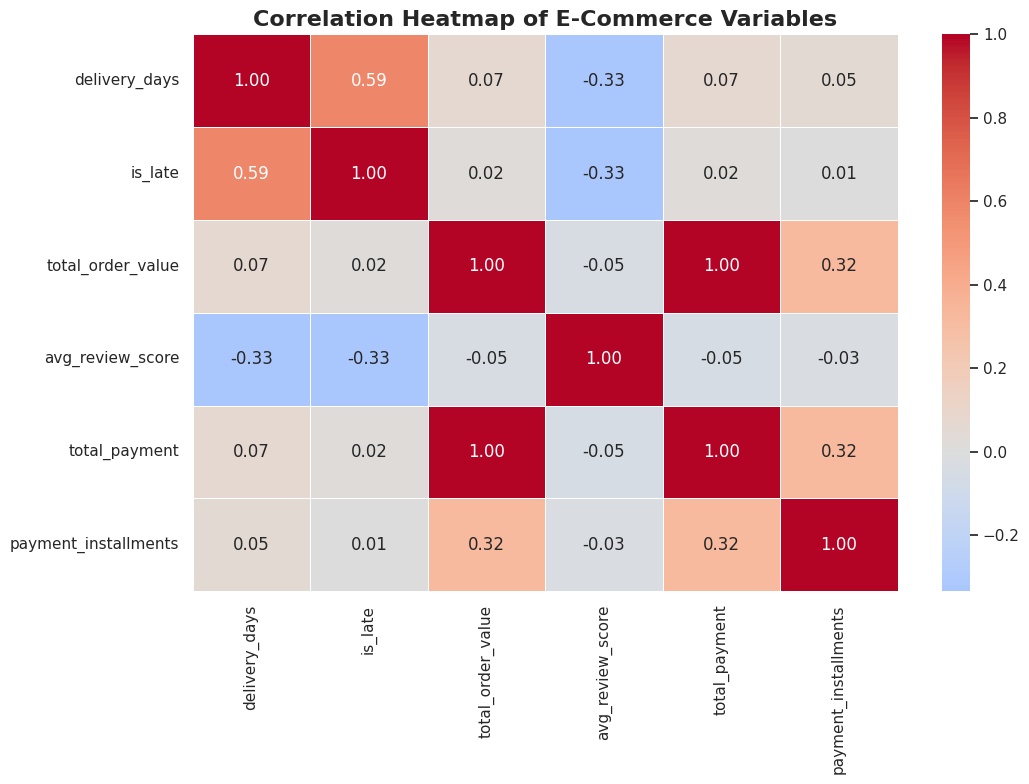

Chart 10 saved successfully!


,delivery_days,is_late,total_order_value,avg_review_score,total_payment,payment_installments
delivery_days,1.000000,0.590141,0.069570,-0.334563,0.069608,0.052408
is_late,0.590141,1.000000,0.016131,-0.328263,0.015444,0.008578
total_order_value,0.069570,0.016131,1.000000,-0.046345,0.999987,0.319862
avg_review_score,-0.334563,-0.328263,-0.046345,1.000000,-0.048546,-0.030977
total_payment,0.069608,0.015444,0.999987,-0.048546,1.000000,0.319090
payment_installments,0.052408,0.008578,0.319862,-0.030977,0.319090,1.000000


In [43]:

# CHART 10: CORRELATION HEATMAP

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Select numerical columns
correlation_columns = [
    "delivery_days",
    "is_late",
    "total_order_value",
    "avg_review_score",
    "total_payment",
    "payment_installments"
]

# Create numerical dataset
correlation_data = olist_clean[
    correlation_columns
].copy()

# Calculate correlation matrix
correlation_matrix = correlation_data.corr(
    method="pearson"
)

# Create heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title(
    "Correlation Heatmap of E-Commerce Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "/content/images/chart_10_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 10 saved successfully!")
display(correlation_matrix)


In [44]:
import os

image_files = sorted(
    f for f in os.listdir("/content/images")
    if f.endswith(".png")
)

print("Total saved charts:", len(image_files))

for file in image_files:
    print("✓", file)

Total saved charts: 10
✓ chart_01_monthly_revenue.png
✓ chart_02_top_categories.png
✓ chart_03_top_states.png
✓ chart_04_delivery_distribution.png
✓ chart_05_review_distribution.png
✓ chart_06_late_vs_review.png
✓ chart_07_weekday_hour_heatmap.png
✓ chart_08_payment_distribution.png
✓ chart_09_price_vs_freight.png
✓ chart_10_correlation_heatmap.png


In [45]:

# PHASE 5: CUSTOMER SEGMENTATION
# STEP 1: PREPARE CUSTOMER PURCHASE DATA

import pandas as pd
import numpy as np

# Start with orders and customer information
rfm_data = orders_features.merge(
    customers_clean[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

# Keep delivered orders with valid purchase dates
rfm_data = rfm_data[
    (rfm_data["order_status"] == "delivered") &
    (rfm_data["order_purchase_timestamp"].notna()) &
    (rfm_data["customer_unique_id"].notna())
].copy()

# Calculate order value from order items
order_values = (
    order_items_clean
    .groupby("order_id", as_index=False)
    .agg(
        monetary_value=("price", "sum")
    )
)

# Attach order value
rfm_data = rfm_data.merge(
    order_values,
    on="order_id",
    how="left"
)

# Remove records without monetary value
rfm_data = rfm_data.dropna(
    subset=["monetary_value"]
)

# Define reference date as one day after the latest purchase
snapshot_date = (
    rfm_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

print("Customer purchase data prepared successfully!")

print("\nTotal delivered orders:", len(rfm_data))
print(
    "Unique customers:",
    rfm_data["customer_unique_id"].nunique()
)
print("Snapshot date:", snapshot_date)

display(rfm_data.head())


Customer purchase data prepared successfully!

Total delivered orders: 96478
Unique customers: 93358
Snapshot date: 2018-08-30 15:00:37


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,order_month,order_weekday,order_hour,total_order_value,customer_unique_id,monetary_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,0,10,Monday,10,38.71,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,0,7,Tuesday,20,141.46,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,0,8,Wednesday,8,179.12,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,0,11,Saturday,19,72.20,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,0,2,Tuesday,21,28.62,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [46]:

# PHASE 5 - STEP 2: RFM ANALYSIS

# Calculate RFM metrics for each customer
rfm = (
    rfm_data
    .groupby("customer_unique_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=("order_id", "nunique"),
        Monetary=("monetary_value", "sum")
    )
    .reset_index()
)

# Round monetary values
rfm["Monetary"] = rfm["Monetary"].round(2)

# Display RFM results
print("RFM Analysis completed successfully!")

print("\nTotal unique customers:", len(rfm))

print("\nRFM Dataset Preview:")
display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


RFM Analysis completed successfully!

Total unique customers: 93358

RFM Dataset Preview:


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,141.621480
std,152.591453,0.209097,215.694014
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.730000
75%,346.000000,1.000000,154.737500
max,714.000000,15.000000,13440.000000


In [47]:

# PHASE 5 - STEP 3: FEATURE SCALING

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Select RFM features
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Check for missing and infinite values
rfm_features = rfm_features.replace(
    [np.inf, -np.inf], np.nan
)

if rfm_features.isnull().any().any():
    raise ValueError("RFM features contain missing values.")

# Apply StandardScaler
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

# Convert scaled data back to DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("RFM scaling completed successfully!")

print("\nScaled RFM data:")
display(rfm_scaled_df.head(10))

print("\nScaled feature means:")
print(rfm_scaled_df.mean().round(3))

print("\nScaled feature standard deviations:")
print(rfm_scaled_df.std().round(3))


RFM scaling completed successfully!

Scaled RFM data:


,Recency,Frequency,Monetary
0,-0.825357,-0.159829,-0.054343
1,-0.805697,-0.159829,-0.568964
2,1.959873,-0.159829,-0.336689
3,0.544321,-0.159829,-0.536093
4,0.328056,-0.159829,0.177931
5,-0.602539,-0.159829,0.057390
6,-0.694288,-0.159829,-0.526821
7,-0.360060,-0.159829,1.114448
8,1.999194,-0.159829,-0.030699
9,-0.445255,-0.159829,-0.170249



Scaled feature means:
Recency     -0.0
Frequency   -0.0
Monetary     0.0
dtype: float64

Scaled feature standard deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


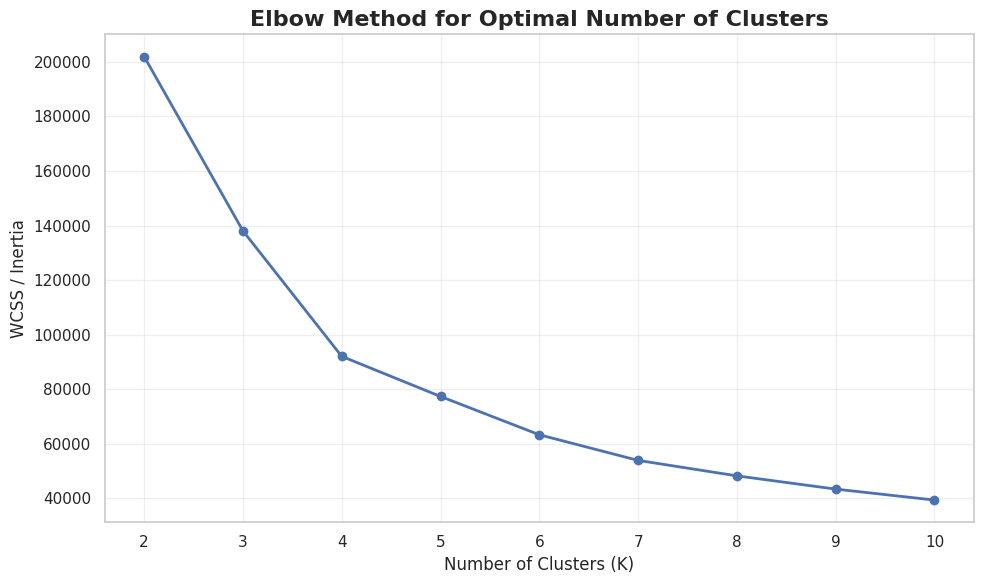

Elbow Method completed successfully!
Check the graph to identify the elbow point.


In [48]:

# PHASE 5 - STEP 4: ELBOW METHOD

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import os

os.makedirs("/content/images", exist_ok=True)

# Test different numbers of clusters
inertia_values = []
k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled_df)

    inertia_values.append(kmeans.inertia_)

# Create Elbow chart
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title(
    "Elbow Method for Optimal Number of Clusters",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "/content/images/chart_11_elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Elbow Method completed successfully!")
print("Check the graph to identify the elbow point.")


In [49]:

# PHASE 5 - STEP 5: K-MEANS CUSTOMER SEGMENTATION

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Test different cluster counts
silhouette_results = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    # Use a sample to calculate silhouette efficiently
    score = silhouette_score(
        rfm_scaled_df,
        labels,
        sample_size=min(10000, len(rfm_scaled_df)),
        random_state=42
    )

    silhouette_results.append({
        "clusters": k,
        "silhouette_score": score
    })

# Display comparison
silhouette_df = pd.DataFrame(silhouette_results)

print("Silhouette Score Comparison:")
display(silhouette_df)

# Select the best scoring cluster count
optimal_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette_score"].idxmax(),
        "clusters"
    ]
)

print("Selected number of clusters:", optimal_k)

# Train final K-Means model
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans_final.fit_predict(
    rfm_scaled_df
)

# Display cluster assignments
print("\nK-Means model trained successfully!")
print("\nCustomer cluster counts:")

display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

display(rfm.head(10))


Silhouette Score Comparison:


,clusters,silhouette_score
0,2,0.738986
1,3,0.461633
2,4,0.493192
3,5,0.416129
4,6,0.432515
5,7,0.435684


Selected number of clusters: 2

K-Means model trained successfully!

Customer cluster counts:


,customer_count
Cluster,
0,2807
1,90551


,customer_unique_id,Recency,Frequency,Monetary,Cluster
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,1
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,1
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,1
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,1
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,1
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,1


In [50]:

# PHASE 5 - STEP 6: CUSTOMER SEGMENT PROFILING

# Calculate average RFM values for each cluster
cluster_summary = (
    rfm.groupby("Cluster")
    .agg(
        total_customers=("customer_unique_id", "count"),
        avg_recency=("Recency", "mean"),
        avg_frequency=("Frequency", "mean"),
        avg_monetary=("Monetary", "mean"),
        total_revenue=("Monetary", "sum")
    )
    .round(2)
    .reset_index()
)

# Sort clusters by average spending
cluster_summary = cluster_summary.sort_values(
    "avg_monetary",
    ascending=False
)

print("CUSTOMER SEGMENT ANALYSIS")
print("=" * 60)

display(cluster_summary)

print("\nTotal segmented customers:", rfm["customer_unique_id"].nunique())
print("Total clusters:", rfm["Cluster"].nunique())


CUSTOMER SEGMENT ANALYSIS


,Cluster,total_customers,avg_recency,avg_frequency,avg_monetary,total_revenue
0,0,2807,220.44,2.11,276.06,774906.35
1,1,90551,238.48,1.00,137.45,12446591.76



Total segmented customers: 93358
Total clusters: 2


In [51]:

# PHASE 5 - STEP 7: ASSIGN CUSTOMER SEGMENT NAMES

import pandas as pd
import numpy as np

# Calculate relative RFM performance of each cluster
profiles = cluster_summary.copy()

# Higher score means better customer value:
# Lower recency is better; higher frequency and monetary are better.
profiles["value_score"] = (
    profiles["avg_recency"].rank(pct=True, ascending=False)
    + profiles["avg_frequency"].rank(pct=True)
    + profiles["avg_monetary"].rank(pct=True)
)

# Rank clusters from highest to lowest value
profiles = profiles.sort_values(
    "value_score",
    ascending=False
).reset_index(drop=True)

# Assign names according to the number of clusters
segment_names = {
    2: ["High Value Customers", "At-Risk Customers"],
    3: ["Champions", "Potential Customers", "At-Risk Customers"],
    4: ["Champions", "Loyal Customers",
        "Potential Customers", "At-Risk Customers"],
    5: ["Champions", "Loyal Customers",
        "Potential Loyalists", "At-Risk Customers",
        "Hibernating Customers"],
    6: ["Champions", "Loyal Customers",
        "Potential Loyalists", "Recent Customers",
        "At-Risk Customers", "Hibernating Customers"],
    7: ["Champions", "Loyal Customers",
        "Potential Loyalists", "Recent Customers",
        "Needs Attention", "At-Risk Customers",
        "Hibernating Customers"]
}

k = len(profiles)

if k not in segment_names:
    raise ValueError("Unexpected cluster count. Expected between 2 and 7.")

# Map actual cluster IDs to segment names
cluster_to_segment = {
    int(row["Cluster"]): segment_names[k][i]
    for i, (_, row) in enumerate(profiles.iterrows())
}

# Add segment names to customer records
rfm["Customer_Segment"] = rfm["Cluster"].map(
    cluster_to_segment
)

print("Customer segments assigned successfully!")

print("\nCustomer Segment Summary:")

segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("Recency", "mean"),
        avg_frequency=("Frequency", "mean"),
        avg_monetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("customers", ascending=False)
)

display(segment_summary)


Customer segments assigned successfully!

Customer Segment Summary:


,customers,avg_recency,avg_frequency,avg_monetary
Customer_Segment,,,,
At-Risk Customers,90551,238.48,1.00,137.45
High Value Customers,2807,220.44,2.11,276.06


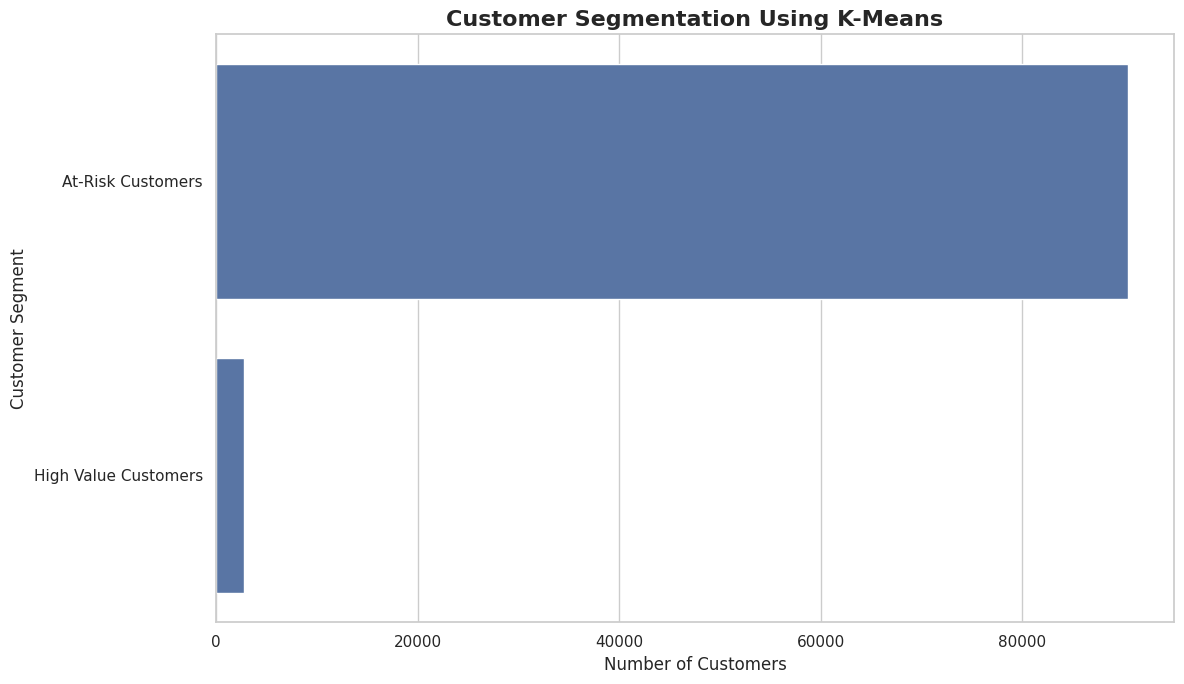

Customer segmentation chart saved successfully!


,Customer_Segment,Customers
0,At-Risk Customers,90551
1,High Value Customers,2807


In [52]:

# CUSTOMER SEGMENT VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/images", exist_ok=True)

# Count customers in each segment
segment_counts = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = ["Customer_Segment", "Customers"]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=segment_counts,
    x="Customers",
    y="Customer_Segment"
)

plt.title(
    "Customer Segmentation Using K-Means",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()

plt.savefig(
    "/content/images/chart_12_customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Customer segmentation chart saved successfully!")
display(segment_counts)


In [53]:
# EXPORT CUSTOMER SEGMENTATION RESULTS

rfm.to_csv(
    "/content/customer_segmentation.csv",
    index=False
)

segment_summary.to_csv(
    "/content/customer_segment_summary.csv"
)

print("Customer segmentation files saved successfully!")
print("1. customer_segmentation.csv")
print("2. customer_segment_summary.csv")

Customer segmentation files saved successfully!
1. customer_segmentation.csv
2. customer_segment_summary.csv


In [54]:
from google.colab import files

files.download("/content/customer_segmentation.csv")
files.download("/content/customer_segment_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:

# PHASE 6 - STEP 1: DASHBOARD KPI CALCULATIONS

import pandas as pd
import numpy as np
import os

# Ensure the dashboard folder exists
os.makedirs("/content/dashboard", exist_ok=True)

# Use delivered orders for revenue calculations
dashboard_orders = olist_clean[
    olist_clean["order_status"] == "delivered"
].copy()

# KPI 1: Total Revenue
total_revenue = dashboard_orders[
    "total_order_value"
].sum()

# KPI 2: Total Orders
total_orders = dashboard_orders[
    "order_id"
].nunique()

# KPI 3: Average Order Value
average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

# KPI 4: Average Review Score
average_review_score = (
    dashboard_orders["avg_review_score"].mean()
)

# KPI 5: Late Delivery Percentage
valid_delivery_orders = dashboard_orders[
    dashboard_orders["order_delivered_customer_date"].notna()
    & dashboard_orders["order_estimated_delivery_date"].notna()
]

late_delivery_percentage = (
    (
        valid_delivery_orders["order_delivered_customer_date"]
        > valid_delivery_orders["order_estimated_delivery_date"]
    ).mean() * 100
    if len(valid_delivery_orders) > 0 else 0
)

# Display KPI results
kpi_data = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Average Review Score",
        "Late Delivery Percentage"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        round(average_review_score, 2),
        round(late_delivery_percentage, 2)
    ]
})

print("DASHBOARD KPI CALCULATIONS COMPLETED!")
display(kpi_data)


DASHBOARD KPI CALCULATIONS COMPLETED!


,KPI,Value
0,Total Revenue,15419773.75
1,Total Orders,96478.00
2,Average Order Value,159.83
3,Average Review Score,4.16
4,Late Delivery Percentage,8.11


In [56]:

# PHASE 6 - STEP 2: INTERACTIVE DASHBOARD CHARTS

import plotly.express as px
import pandas as pd
import os

os.makedirs("/content/dashboard", exist_ok=True)

# --------------------------------
# CHART 1: MONTHLY REVENUE TREND
# --------------------------------

monthly_data = dashboard_orders.copy()

monthly_data["month"] = (
    monthly_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_revenue = (
    monthly_data.groupby("month", as_index=False)
    ["total_order_value"]
    .sum()
)

fig1 = px.line(
    monthly_revenue,
    x="month",
    y="total_order_value",
    markers=True,
    title="Monthly Revenue Trend",
    labels={
        "month": "Month",
        "total_order_value": "Revenue (R$)"
    }
)

fig1.update_layout(template="plotly_white")


# --------------------------------
# CHART 2: TOP 10 PRODUCT CATEGORIES
# --------------------------------

category_data = order_items_clean.merge(
    orders_clean[["order_id", "order_status"]],
    on="order_id",
    how="inner"
)

category_data = category_data[
    category_data["order_status"] == "delivered"
].merge(
    products_translated[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left"
)

category_data["product_category_name_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown")
)

top_categories = (
    category_data.groupby(
        "product_category_name_english",
        as_index=False
    )["price"]
    .sum()
    .sort_values("price", ascending=False)
    .head(10)
)

fig2 = px.bar(
    top_categories.sort_values("price"),
    x="price",
    y="product_category_name_english",
    orientation="h",
    title="Top 10 Product Categories by Revenue",
    labels={
        "price": "Revenue (R$)",
        "product_category_name_english": "Category"
    }
)

fig2.update_layout(template="plotly_white")


# --------------------------------
# CHART 3: TOP 10 CUSTOMER STATES
# --------------------------------

state_data = dashboard_orders.merge(
    customers_clean[
        ["customer_id", "customer_state"]
    ],
    on="customer_id",
    how="left"
)

state_summary = (
    state_data.groupby("customer_state", as_index=False)
    .agg(total_orders=("order_id", "nunique"))
    .sort_values("total_orders", ascending=False)
    .head(10)
)

fig3 = px.bar(
    state_summary,
    x="customer_state",
    y="total_orders",
    title="Top 10 Customer States by Orders",
    labels={
        "customer_state": "State",
        "total_orders": "Delivered Orders"
    }
)

fig3.update_layout(template="plotly_white")


# --------------------------------
# CHART 4: DELIVERY PERFORMANCE
# --------------------------------

delivery_data = dashboard_orders[
    dashboard_orders["delivery_days"].notna()
    & (dashboard_orders["delivery_days"] >= 0)
].copy()

fig4 = px.histogram(
    delivery_data,
    x="delivery_days",
    nbins=35,
    title="Distribution of Delivery Days",
    labels={
        "delivery_days": "Delivery Days"
    }
)

fig4.update_layout(template="plotly_white")


# --------------------------------
# CHART 5: CUSTOMER REVIEW SCORES
# --------------------------------

review_data = dashboard_orders[
    dashboard_orders["avg_review_score"].notna()
].copy()

review_summary = (
    review_data["avg_review_score"]
    .round()
    .value_counts()
    .sort_index()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("review_score")
    .reset_index(name="total_reviews")
)

fig5 = px.bar(
    review_summary,
    x="review_score",
    y="total_reviews",
    title="Customer Review Score Distribution",
    labels={
        "review_score": "Review Score",
        "total_reviews": "Number of Orders"
    }
)

fig5.update_layout(
    template="plotly_white",
    xaxis=dict(tickmode="array", tickvals=[1, 2, 3, 4, 5])
)


# --------------------------------
# CHART 6: CUSTOMER SEGMENTATION
# --------------------------------

segment_data = (
    rfm.groupby("Customer_Segment", as_index=False)
    .agg(customers=("customer_unique_id", "count"))
)

fig6 = px.pie(
    segment_data,
    names="Customer_Segment",
    values="customers",
    hole=0.4,
    title="Customer Segmentation Distribution"
)

fig6.update_layout(template="plotly_white")


# --------------------------------
# DISPLAY ALL SIX CHARTS
# --------------------------------

print("Six interactive dashboard charts created!")

for number, figure in enumerate(
    [fig1, fig2, fig3, fig4, fig5, fig6],
    start=1
):
    print(f"Dashboard Chart {number}")
    figure.show()

print("\nAll six Plotly charts created successfully!")


KeyError: 'customer_state'

In [57]:

# PHASE 6 - STEP 2: CREATE SIX INTERACTIVE CHARTS

import plotly.express as px
import pandas as pd
import os

os.makedirs("/content/dashboard", exist_ok=True)

# --------------------------------
# CHART 1: MONTHLY REVENUE
# --------------------------------

monthly_data = dashboard_orders.copy()

monthly_data["month"] = (
    monthly_data["order_purchase_timestamp"]
    .dt.to_period("M").astype(str)
)

monthly_revenue = (
    monthly_data.groupby("month", as_index=False)
    ["total_order_value"].sum()
)

fig1 = px.line(
    monthly_revenue,
    x="month",
    y="total_order_value",
    markers=True,
    title="Monthly Revenue Trend",
    labels={
        "month": "Month",
        "total_order_value": "Revenue (R$)"
    }
)


# --------------------------------
# CHART 2: TOP 10 CATEGORIES
# --------------------------------

category_data = order_items_clean.merge(
    orders_clean[["order_id", "order_status"]],
    on="order_id",
    how="inner"
)

category_data = category_data[
    category_data["order_status"] == "delivered"
]

category_data = category_data.merge(
    products_translated[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left"
)

category_data["product_category_name_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown")
)

top_categories = (
    category_data.groupby(
        "product_category_name_english",
        as_index=False
    )["price"].sum()
    .sort_values("price", ascending=False)
    .head(10)
)

fig2 = px.bar(
    top_categories.sort_values("price"),
    x="price",
    y="product_category_name_english",
    orientation="h",
    title="Top 10 Product Categories by Revenue"
)


# --------------------------------
# CHART 3: TOP 10 CUSTOMER STATES
# --------------------------------

# Use customer_state already present in olist_clean
state_summary = (
    dashboard_orders.groupby("customer_state", as_index=False)
    .agg(total_orders=("order_id", "nunique"))
    .sort_values("total_orders", ascending=False)
    .head(10)
)

fig3 = px.bar(
    state_summary,
    x="customer_state",
    y="total_orders",
    title="Top 10 Customer States by Orders",
    labels={
        "customer_state": "Customer State",
        "total_orders": "Delivered Orders"
    }
)


# --------------------------------
# CHART 4: DELIVERY PERFORMANCE
# --------------------------------

delivery_data = dashboard_orders[
    dashboard_orders["delivery_days"].notna()
    & (dashboard_orders["delivery_days"] >= 0)
].copy()

fig4 = px.histogram(
    delivery_data,
    x="delivery_days",
    nbins=35,
    title="Distribution of Delivery Days",
    labels={"delivery_days": "Delivery Days"}
)


# --------------------------------
# CHART 5: REVIEW DISTRIBUTION
# --------------------------------

review_data = dashboard_orders.dropna(
    subset=["avg_review_score"]
).copy()

review_summary = (
    review_data["avg_review_score"]
    .round()
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("review_score")
    .reset_index(name="total_reviews")
)

fig5 = px.bar(
    review_summary,
    x="review_score",
    y="total_reviews",
    title="Customer Review Score Distribution"
)


# --------------------------------
# CHART 6: CUSTOMER SEGMENTATION
# --------------------------------

segment_summary_dashboard = (
    rfm.groupby("Customer_Segment", as_index=False)
    .agg(customers=("customer_unique_id", "nunique"))
)

fig6 = px.pie(
    segment_summary_dashboard,
    names="Customer_Segment",
    values="customers",
    hole=0.4,
    title="Customer Segmentation Distribution"
)


# --------------------------------
# DISPLAY ALL SIX CHARTS
# --------------------------------

figures = [fig1, fig2, fig3, fig4, fig5, fig6]

for i, fig in enumerate(figures, start=1):
    fig.update_layout(template="plotly_white")
    print(f"Dashboard Chart {i}")
    fig.show()

print("\nSUCCESS: All six interactive charts created!")


Dashboard Chart 1


Dashboard Chart 2


Dashboard Chart 3


Dashboard Chart 4


Dashboard Chart 5


Dashboard Chart 6



SUCCESS: All six interactive charts created!


In [58]:

# PHASE 6 - STEP 3: BUILD EXECUTIVE DASHBOARD

import os
from IPython.display import display, HTML

# Create dashboard directory
os.makedirs("/content/dashboard", exist_ok=True)

# Store all six charts
figures = [fig1, fig2, fig3, fig4, fig5, fig6]

# Convert charts into HTML
chart_html = []

for i, fig in enumerate(figures, start=1):
    chart_html.append(
        f"""
        <section class="chart-card">
            {fig.to_html(
                full_html=False,
                include_plotlyjs="cdn" if i == 1 else False,
                config={"responsive": True}
            )}
        </section>
        """
    )

# Create complete dashboard HTML
dashboard_html = f"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>Olist E-Commerce Executive Dashboard</title>

<style>
* {{
    box-sizing: border-box;
}}

body {{
    margin: 0;
    padding: 25px;
    background: #f3f6fb;
    color: #1e293b;
    font-family: Arial, sans-serif;
}}

.container {{
    max-width: 1450px;
    margin: auto;
}}

.header {{
    background: #172554;
    color: white;
    padding: 30px;
    border-radius: 15px;
    margin-bottom: 25px;
}}

.header h1 {{
    margin: 0 0 10px;
}}

.header p {{
    margin: 0;
    color: #cbd5e1;
}}

.kpi-grid {{
    display: grid;
    grid-template-columns: repeat(auto-fit, minmax(200px, 1fr));
    gap: 18px;
    margin-bottom: 25px;
}}

.kpi-card {{
    background: white;
    padding: 24px;
    border-radius: 12px;
    box-shadow: 0 3px 12px rgba(0,0,0,0.05);
}}

.kpi-card h3 {{
    color: #64748b;
    font-size: 14px;
    margin: 0 0 12px;
}}

.kpi-card p {{
    color: #1d4ed8;
    font-size: 25px;
    font-weight: bold;
    margin: 0;
}}

.section-title {{
    margin: 30px 0 15px;
}}

.chart-grid {{
    display: grid;
    grid-template-columns: repeat(2, minmax(0, 1fr));
    gap: 20px;
}}

.chart-card {{
    background: white;
    border-radius: 12px;
    padding: 12px;
    min-width: 0;
    box-shadow: 0 3px 12px rgba(0,0,0,0.05);
}}

.footer {{
    text-align: center;
    padding: 25px;
    color: #64748b;
    margin-top: 25px;
}}

@media(max-width: 850px) {{
    .chart-grid {{
        grid-template-columns: 1fr;
    }}
}}

</style>
</head>

<body>

<div class="container">

    <header class="header">
        <h1>Olist E-Commerce Analytics</h1>
        <p>Executive Sales & Customer Insights Dashboard</p>
        <p>Business Performance | Delivery | Customer Experience</p>
    </header>

    <h2 class="section-title">Business Performance KPIs</h2>

    <div class="kpi-grid">

        <div class="kpi-card">
            <h3>Total Revenue</h3>
            <p>R$ {total_revenue:,.2f}</p>
        </div>

        <div class="kpi-card">
            <h3>Total Delivered Orders</h3>
            <p>{total_orders:,}</p>
        </div>

        <div class="kpi-card">
            <h3>Average Order Value</h3>
            <p>R$ {average_order_value:,.2f}</p>
        </div>

        <div class="kpi-card">
            <h3>Average Review Score</h3>
            <p>{average_review_score:.2f} / 5</p>
        </div>

        <div class="kpi-card">
            <h3>Late Delivery Rate</h3>
            <p>{late_delivery_percentage:.2f}%</p>
        </div>

    </div>

    <h2 class="section-title">Interactive Business Analysis</h2>

    <div class="chart-grid">
        {''.join(chart_html)}
    </div>

    <footer class="footer">
        <p>Olist E-Commerce Analytics Project</p>
        <p>Developed using Python, Pandas, SQL and Plotly</p>
    </footer>

</div>

</body>
</html>
"""

# Save dashboard
dashboard_path = "/content/dashboard/dashboard.html"

with open(dashboard_path, "w", encoding="utf-8") as file:
    file.write(dashboard_html)

print("Executive dashboard created successfully!")
print("Dashboard location:", dashboard_path)
print("Total KPI cards: 5")
print("Total interactive charts:", len(figures))
print("File size:", round(os.path.getsize(dashboard_path) / 1024, 2), "KB")

# Display a preview
display(HTML(
    "<h2>Dashboard HTML generated successfully!</h2>"
    "<p>Download the file to view your complete dashboard.</p>"
))


Executive dashboard created successfully!
Dashboard location: /content/dashboard/dashboard.html
Total KPI cards: 5
Total interactive charts: 6
File size: 1757.37 KB


In [59]:
from google.colab import files

files.download("/content/dashboard/dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:

# PHASE 7 - STEP 1: BUSINESS INSIGHTS

import pandas as pd
import numpy as np

# 1. Total delivered orders
total_orders = dashboard_orders["order_id"].nunique()

# 2. Total revenue
total_revenue = dashboard_orders["total_order_value"].sum()

# 3. Average order value
average_order_value = total_revenue / total_orders

# 4. Average review score
average_review = dashboard_orders[
    "avg_review_score"
].mean()

# 5. Late delivery percentage
valid_delivery = dashboard_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

late_orders = (
    valid_delivery["order_delivered_customer_date"]
    > valid_delivery["order_estimated_delivery_date"]
).sum()

late_percentage = (
    late_orders / len(valid_delivery) * 100
    if len(valid_delivery) > 0 else 0
)

# 6. Highest revenue product category
top_category = top_categories.iloc[0]

# 7. Highest ordering customer state
top_state = state_summary.iloc[0]

# 8. Most popular payment method
top_payment = (
    payments_clean["payment_type"]
    .value_counts()
    .idxmax()
)

# 9. Average delivery days
average_delivery = delivery_data[
    "delivery_days"
].mean()

# 10. Largest customer segment
largest_segment = segment_summary[
    "customers"
].idxmax()

# Display insights
insights = [
    ("Total Delivered Orders", f"{total_orders:,}"),
    ("Total Revenue", f"R$ {total_revenue:,.2f}"),
    ("Average Order Value", f"R$ {average_order_value:,.2f}"),
    ("Average Review Score", f"{average_review:.2f}/5"),
    ("Late Delivery Rate", f"{late_percentage:.2f}%"),
    (
        "Top Product Category",
        str(top_category["product_category_name_english"])
    ),
    (
        "Top Customer State",
        str(top_state["customer_state"])
    ),
    ("Most Used Payment Method", str(top_payment)),
    ("Average Delivery Days", f"{average_delivery:.2f} days"),
    ("Largest Customer Segment", str(largest_segment))
]

insights_df = pd.DataFrame(
    insights,
    columns=["Business Metric", "Actual Result"]
)

print("10 BUSINESS INSIGHTS GENERATED!")
display(insights_df)

# Save insights
insights_df.to_csv(
    "/content/business_insights.csv",
    index=False
)


10 BUSINESS INSIGHTS GENERATED!


,Business Metric,Actual Result
0,Total Delivered Orders,"96,478"
1,Total Revenue,"R$ 15,419,773.75"
2,Average Order Value,R$ 159.83
3,Average Review Score,4.16/5
4,Late Delivery Rate,8.11%
5,Top Product Category,health_beauty
6,Top Customer State,SP
7,Most Used Payment Method,credit_card
8,Average Delivery Days,12.56 days
9,Largest Customer Segment,At-Risk Customers


In [61]:

# PHASE 7 - STEP 2: BUSINESS RECOMMENDATIONS

recommendations = [
    {
        "Area": "Customer Experience",
        "Recommendation": "Investigate late deliveries and improve logistics coordination.",
        "Business Goal": "Improve customer satisfaction."
    },
    {
        "Area": "Marketing",
        "Recommendation": "Create targeted campaigns for high-value and loyal customers.",
        "Business Goal": "Increase customer retention."
    },
    {
        "Area": "Product Strategy",
        "Recommendation": "Prioritize high-revenue product categories and review underperforming categories.",
        "Business Goal": "Improve product sales."
    },
    {
        "Area": "Regional Growth",
        "Recommendation": "Focus marketing and seller partnerships in high-order customer states.",
        "Business Goal": "Increase regional sales."
    },
    {
        "Area": "Payment Strategy",
        "Recommendation": "Optimize the checkout experience around popular payment methods.",
        "Business Goal": "Improve purchase conversion."
    }
]

recommendations_df = pd.DataFrame(recommendations)

print("FIVE BUSINESS RECOMMENDATIONS CREATED!")

display(recommendations_df)

# Save recommendations
recommendations_df.to_csv(
    "/content/business_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")


FIVE BUSINESS RECOMMENDATIONS CREATED!


,Area,Recommendation,Business Goal
0,Customer Experience,Investigate late deliveries and improve logist...,Improve customer satisfaction.
1,Marketing,Create targeted campaigns for high-value and l...,Increase customer retention.
2,Product Strategy,Prioritize high-revenue product categories and...,Improve product sales.
3,Regional Growth,Focus marketing and seller partnerships in hig...,Increase regional sales.
4,Payment Strategy,Optimize the checkout experience around popula...,Improve purchase conversion.


Recommendations saved successfully!


In [62]:
import shutil
from google.colab import files

# Create a ZIP file containing all chart images
shutil.make_archive(
    "/content/project_images",
    "zip",
    "/content/images"
)

# Download the ZIP file
files.download("/content/project_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>